# Gulf Carriers on US Routes: Load Factor, Capacity & Network Analysis (2024)

**Business question:** How does Etihad's US network perform against its Gulf peers, Emirates and Qatar Airways, and what do the capacity and load factor signals suggest about where demand is strongest?

**Data:** U.S. DOT Bureau of Transportation Statistics (BTS) **T-100 Segment** data, 2024. Every carrier flying to or from the US reports monthly seats, passengers, departures and distance per non-stop segment. This notebook uses the rows for Etihad (EY), Emirates (EK) and Qatar Airways (QR).

**KPIs used**

| KPI | Definition |
|---|---|
| **Load factor (LF)** | Passengers ÷ seats. The share of seats filled. |
| **ASK** | Available Seat Kilometres: seats × distance (km). Capacity. |
| **RPK** | Revenue Passenger Kilometres: passengers × distance (km). Traffic. |
| **Passenger LF (km-weighted)** | RPK ÷ ASK. Load factor weighted by distance. |
| **Gauge** | Average seats per departure. Aircraft size used on a route. |

> **PRASK** (passenger revenue per ASK) = yield × load factor. T-100 has no fare or revenue data, so this analysis covers the **load factor side** of the PRASK equation only.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option('display.width', 160)
MILES_TO_KM = 1.609344

# Fixed colour per carrier (entity), never by rank
COL = {'Etihad': '#2a78d6', 'Emirates': '#eb6834', 'Qatar Airways': '#1baf7a'}
INK, INK2, GRID, SURF = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
plt.rcParams.update({'figure.facecolor': SURF, 'axes.facecolor': SURF, 'axes.edgecolor': GRID,
                     'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
                     'text.color': INK, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID,
                     'grid.linewidth': 0.8, 'savefig.dpi': 160, 'savefig.bbox': 'tight'})

raw = pd.read_csv('../data/raw/t100_segment_gulf_carriers_2024.csv')
types = pd.read_csv('../data/lookups/L_AIRCRAFT_TYPE.csv').rename(columns={'Code': 'AIRCRAFT_TYPE', 'Description': 'aircraft'})
raw.shape

(382, 37)

## 1. Data preparation and quality checks

- Keep **scheduled passenger service** only (`CLASS == 'F'`) with seats reported. This removes cargo-only and charter rows.
- Label each segment as **outbound** (from the carrier's hub to the US) or **inbound** (US to hub).
- Check which months each carrier has reported, because uneven coverage would bias comparisons.

In [2]:
name_map = {'Etihad Airways': 'Etihad', 'Emirates': 'Emirates', 'Qatar Airways (Q.C.S.C)': 'Qatar Airways'}
hub_map = {'Etihad': 'AUH', 'Emirates': 'DXB', 'Qatar Airways': 'DOH'}

df = raw.copy()
df['carrier'] = df['UNIQUE_CARRIER_NAME'].map(name_map)
print('Rows by service class:', df['CLASS'].value_counts().to_dict())
df = df[(df['CLASS'] == 'F') & (df['SEATS'] > 0)].copy()

df['hub'] = df['carrier'].map(hub_map)
df['direction'] = np.select([df['ORIGIN'] == df['hub'], df['DEST'] == df['hub']], ['Outbound (hub → US)', 'Inbound (US → hub)'], 'Other')
df['gateway'] = np.where(df['ORIGIN'] == df['hub'], df['DEST'], df['ORIGIN'])
df['dist_km'] = df['DISTANCE'] * MILES_TO_KM
df['ASK'] = df['SEATS'] * df['dist_km']
df['RPK'] = df['PASSENGERS'] * df['dist_km']
df = df.merge(types, on='AIRCRAFT_TYPE', how='left')

coverage = df.pivot_table(index='carrier', columns='MONTH', values='SEATS', aggfunc='sum').notna()
coverage.replace({True: '✓', False: '–'})

Rows by service class: {'F': 326, 'G': 42, 'P': 14}


MONTH,1,2,3,4,5,6,7
carrier,,,,,,,
Emirates,✓,✓,✓,✓,✓,–,–
Etihad,✓,✓,✓,✓,✓,✓,✓
Qatar Airways,✓,✓,✓,✓,✓,✓,–


**Finding:** reporting coverage is uneven. In this extract Emirates has data for January–May, Qatar Airways for January–June and Etihad for January–July. To compare like for like, **all comparisons use the common window, January–May 2024**.

Emirates also flies two **fifth-freedom** routes (New York–Athens and New York–Milan) that don't touch Dubai. They're excluded from hub-to-US comparisons.

In [3]:
win = df[df['MONTH'].between(1, 5)].copy()
fifth = win[win['direction'] == 'Other'][['carrier', 'ORIGIN', 'DEST']].drop_duplicates()
print('Fifth-freedom segments excluded:'); print(fifth.to_string(index=False))
win = win[win['direction'] != 'Other']
WEEKS = 152 / 7  # 1 Jan - 31 May 2024
len(win)

Fifth-freedom segments excluded:
 carrier ORIGIN DEST
Emirates    EWR  ATH
Emirates    ATH  EWR
Emirates    JFK  MXP
Emirates    MXP  JFK


265

## 2. Carrier scorecard (Jan–May 2024)

In [4]:
def kpis(g):
    return pd.Series({
        'US gateways': g['gateway'].nunique(),
        'Departures': g['DEPARTURES_PERFORMED'].sum(),
        'Seats': g['SEATS'].sum(),
        'Passengers': g['PASSENGERS'].sum(),
        'Load factor': g['PASSENGERS'].sum() / g['SEATS'].sum(),
        'ASK (m)': g['ASK'].sum() / 1e6,
        'RPK (m)': g['RPK'].sum() / 1e6,
        'Seats per departure': g['SEATS'].sum() / g['DEPARTURES_PERFORMED'].sum(),
    })

score = win.groupby('carrier').apply(kpis).T[['Etihad', 'Emirates', 'Qatar Airways']]
fmt = score.copy().astype(object)
for r in score.index:
    fmt.loc[r] = [f'{v:.1%}' if r == 'Load factor' else f'{v:,.0f}' for v in score.loc[r]]
fmt

carrier,Etihad,Emirates,Qatar Airways
US gateways,4,11,11
Departures,"1,288","3,504","4,494"
Seats,"398,384","1,480,575","1,547,536"
Passengers,"354,832","1,128,966","1,399,555"
Load factor,89.1%,76.3%,90.4%
ASK (m),"4,497","17,979","18,430"
RPK (m),"4,007","13,665","16,698"
Seats per departure,309,423,344


In [5]:
share = win.groupby('carrier')[['SEATS', 'PASSENGERS', 'ASK']].sum()
(share / share.sum()).style.format('{:.1%}').set_caption('Share of Gulf-carrier US capacity and traffic')

,SEATS,PASSENGERS,ASK
carrier,,,
Emirates,43.2%,39.2%,44.0%
Etihad,11.6%,12.3%,11.0%
Qatar Airways,45.2%,48.5%,45.1%


**What this shows**

- **Etihad runs a small but full US network.** It serves 4 US gateways against 11 each for Emirates and Qatar Airways, yet its load factor (89.1%) is far above Emirates (76.3%) and close to Qatar Airways (90.4%).
- Etihad holds only about **12% of Gulf-carrier US seats**. With nearly 9 in 10 seats already filled, demand isn't the constraint on its existing routes; **network breadth** is.
- Emirates flies the biggest aircraft (423 seats per departure, driven by the A380) but fills the fewest of them, so its high capacity comes with a lower load factor.

## 3. Monthly load factor trend

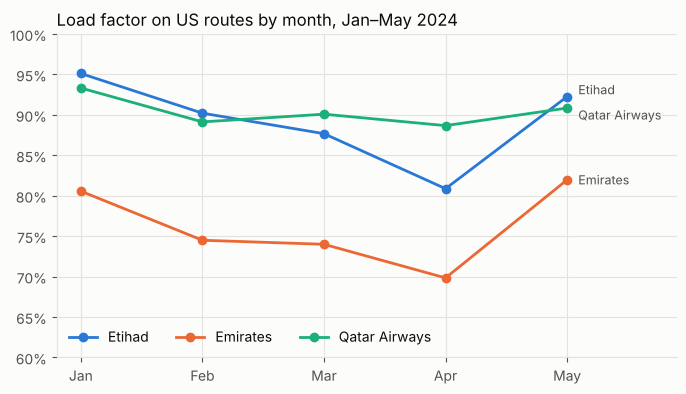

carrier,Etihad,Emirates,Qatar Airways
MONTH,,,
1,95.1%,80.6%,93.3%
2,90.2%,74.5%,89.1%
3,87.7%,74.0%,90.1%
4,80.9%,69.8%,88.7%
5,92.3%,82.0%,90.9%


In [6]:
m = win.groupby(['MONTH', 'carrier'])[['PASSENGERS', 'SEATS']].sum()
m['LF'] = m['PASSENGERS'] / m['SEATS']
lf = m['LF'].unstack()[['Etihad', 'Emirates', 'Qatar Airways']]
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May']

fig, ax = plt.subplots(figsize=(8, 4.2))
for c in lf.columns:
    ax.plot(months, lf[c], color=COL[c], lw=2, marker='o', ms=6, label=c)
    off = {'Etihad': 5, 'Qatar Airways': -5, 'Emirates': 0}[c]
    ax.annotate(c, (4, lf[c].iloc[-1]), xytext=(8, off), textcoords='offset points', va='center', color=INK2, fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_ylim(0.6, 1.0)
ax.set_title('Load factor on US routes by month, Jan–May 2024', loc='left', fontsize=12, color=INK)
ax.legend(frameon=False, loc='lower left', ncol=3)
ax.set_xlim(-0.2, 4.9)
plt.savefig('../images/01_monthly_load_factor.png'); plt.show()
lf.style.format('{:.1%}')

**What this shows**

- All three carriers dip in **March–April**, consistent with Ramadan (11 March – 9 April 2024) and the post-winter shoulder season, then recover in May.
- Etihad's dip is the deepest of the three: from 95.1% in January to 80.9% in April, a 14-point drop against 11 for Emirates and 5 for Qatar Airways. On a small network each route's swings move the total more, and the shoulder months are where revenue management levers (pricing, fare brands, upsell) matter most.

## 4. Directional imbalance: hub → US vs US → hub

A route can be full in one direction and half-empty in the other. Imbalance tells revenue management where to stimulate demand (often with pricing) and tells marketing which point of sale to target.

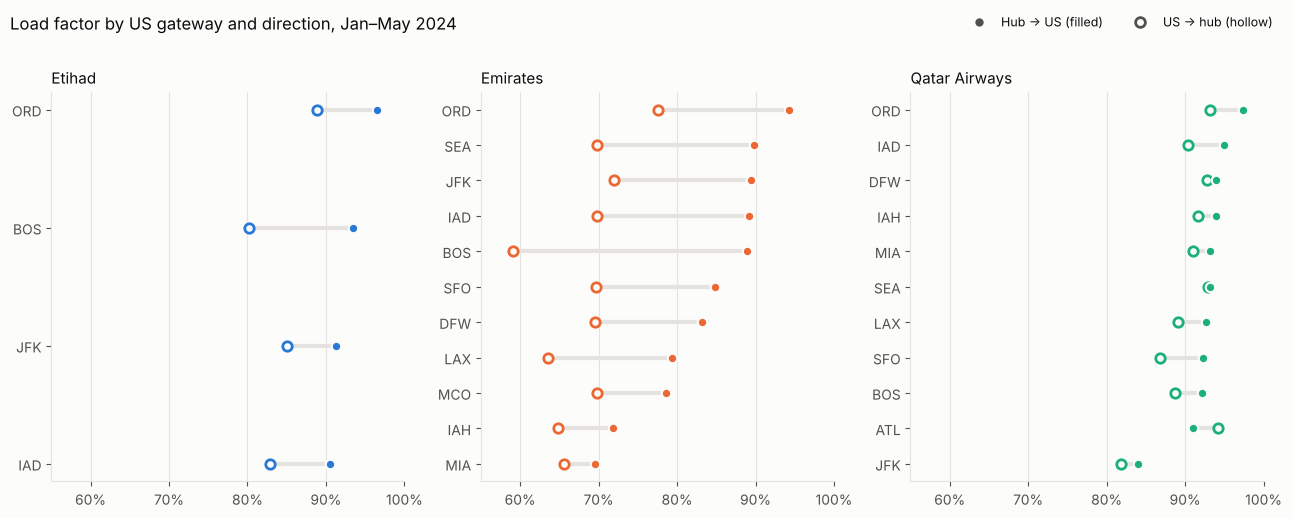

,avg gap (pts),min gap,max gap
carrier,,,
Emirates,15.2,4.0,29.7
Etihad,8.7,6.3,13.2
Qatar Airways,2.4,-3.2,5.5


In [7]:
r = win.groupby(['carrier', 'gateway', 'direction'])[['PASSENGERS', 'SEATS', 'DEPARTURES_PERFORMED']].sum()
r['LF'] = r['PASSENGERS'] / r['SEATS']
d = r['LF'].unstack('direction')
d.columns = ['inbound', 'outbound']
d['gap_pts'] = (d['outbound'] - d['inbound']) * 100

fig, axes = plt.subplots(1, 3, figsize=(13, 5.2), sharex=True)
for ax, c in zip(axes, ['Etihad', 'Emirates', 'Qatar Airways']):
    s = d.loc[c].sort_values('outbound')
    y = np.arange(len(s))
    ax.hlines(y, s['inbound'], s['outbound'], color=GRID, lw=3, zorder=1)
    ax.scatter(s['inbound'], y, s=46, facecolor=SURF, edgecolor=COL[c], lw=2, zorder=2, label='US → hub')
    ax.scatter(s['outbound'], y, s=46, color=COL[c], edgecolor=SURF, lw=1.5, zorder=3, label='Hub → US')
    ax.set_yticks(y, s.index)
    ax.set_title(c, loc='left', color=INK, fontsize=11)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.set_xlim(0.55, 1.0)
    ax.grid(axis='y', visible=False)
from matplotlib.lines import Line2D
handles = [Line2D([], [], ls='', marker='o', ms=7, mfc=INK2, mec=SURF, label='Hub → US (filled)'),
           Line2D([], [], ls='', marker='o', ms=7, mfc=SURF, mec=INK2, mew=2, label='US → hub (hollow)')]
fig.legend(handles=handles, frameon=False, ncol=2, loc='upper right', bbox_to_anchor=(0.99, 1.0), fontsize=9)
fig.suptitle('Load factor by US gateway and direction, Jan–May 2024', x=0.01, ha='left', fontsize=12, color=INK)
plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.savefig('../images/02_directional_load_factor.png'); plt.show()

d.groupby(level=0)['gap_pts'].agg(['mean', 'min', 'max']).round(1).rename(columns={'mean': 'avg gap (pts)', 'min': 'min gap', 'max': 'max gap'})

**What this shows**

- **Emirates has a strong westbound skew:** flights from Dubai into the US average 15 points fuller than flights back, reaching 30 points on Boston and 15–20 on Chicago, New York, Washington and Seattle. The US → Dubai direction is where Emirates has empty seats to fill.
- **Etihad sits in between:** Abu Dhabi → US runs 6–13 points fuller than the return. Even its weaker direction stays above 80%, so demand holds up both ways.
- **Qatar Airways is almost perfectly balanced** (2–3 points on average), the result you'd expect from a carrier pricing actively to fill both directions.
- **Chicago is Etihad's standout route**, the fullest in both directions (96.5% from Abu Dhabi, 88.8% back).

## 5. Gateway coverage: where each carrier flies, and how full

Load factor by gateway (both directions combined). A blank cell means the carrier doesn't serve that gateway.

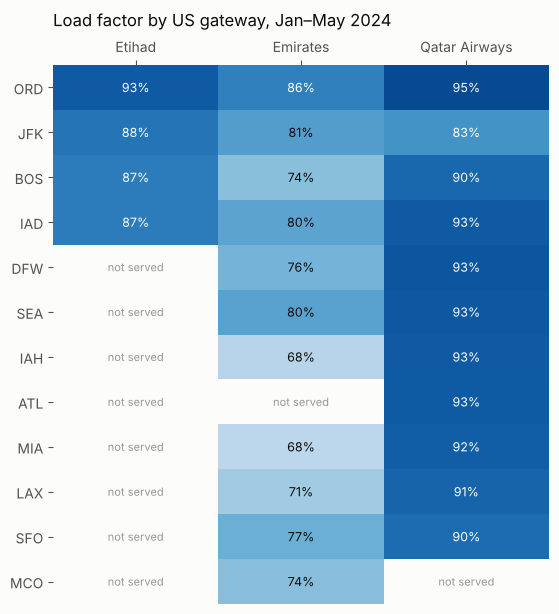

carrier,Etihad,Emirates,Qatar Airways
gateway,,,
ATL,–,–,7.0
BOS,1.7,7.0,7.4
DFW,–,7.0,13.9
IAD,7.0,7.0,10.7
IAH,–,7.0,7.0
JFK,14.0,14.0,20.7
LAX,–,7.0,8.8
MCO,–,5.0,–
MIA,–,7.0,7.0


In [8]:
g = win.groupby(['gateway', 'carrier'])[['PASSENGERS', 'SEATS', 'DEPARTURES_PERFORMED']].sum()
g['LF'] = g['PASSENGERS'] / g['SEATS']
g['weekly_freq'] = g['DEPARTURES_PERFORMED'] / 2 / WEEKS   # round trips per week
grid = g['LF'].unstack()[['Etihad', 'Emirates', 'Qatar Airways']]
grid = grid.loc[grid.notna().sum(axis=1).sort_values(ascending=False).index]
grid = grid.sort_values(['Etihad', 'Qatar Airways'], ascending=False, na_position='last')

fig, ax = plt.subplots(figsize=(6.4, 7))
cmap = plt.cm.Blues
cmap.set_bad(SURF)
im = ax.imshow(grid.values.astype(float), cmap=cmap, vmin=0.55, vmax=1.0, aspect='auto')
ax.set_xticks(range(3), grid.columns); ax.set_yticks(range(len(grid)), grid.index)
ax.xaxis.tick_top(); ax.grid(False)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        if pd.notna(v):
            ax.text(j, i, f'{v:.0%}', ha='center', va='center', fontsize=9, color='white' if v > 0.82 else INK)
        else:
            ax.text(j, i, 'not served', ha='center', va='center', fontsize=8, color='#9a9893')
for s in ax.spines.values(): s.set_visible(False)
ax.set_title('Load factor by US gateway, Jan–May 2024', loc='left', fontsize=12, color=INK, pad=28)
plt.savefig('../images/03_gateway_coverage.png'); plt.show()

g['weekly_freq'].unstack()[['Etihad', 'Emirates', 'Qatar Airways']].round(1).fillna('–')

**What this shows**

- Etihad serves **New York JFK, Chicago, Washington Dulles and Boston**. Emirates and Qatar Airways also fly to **Dallas, Houston, Los Angeles, San Francisco, Seattle and Miami**, plus Atlanta (Qatar only) and Orlando (Emirates only).
- Qatar Airways fills **around 90% of seats or more** at nearly all of those gateways, a sign of strong Gulf-hub demand from those US cities.
- **Caveat:** high load factor is a demand signal, not proof that a new route would be profitable. That depends on yield, cost (CASK), aircraft availability and traffic rights, none of which are in this data.

## 6. Capacity signal: frequency vs load factor on Etihad's routes

In [9]:
ey = g.loc[(slice(None), 'Etihad'), :].droplevel(1)
ey['seats_per_dep'] = ey['SEATS'] / ey['DEPARTURES_PERFORMED']
ac = (win[win.carrier == 'Etihad'].groupby(['gateway', 'aircraft'])['DEPARTURES_PERFORMED'].sum()
      .groupby(level=0).apply(lambda s: ', '.join(f'{a} ({n/s.sum():.0%})' for (_, a), n in s.sort_values(ascending=False).items())))
ey['aircraft (share of departures)'] = ac
ey[['weekly_freq', 'seats_per_dep', 'LF', 'aircraft (share of departures)']].sort_values('LF', ascending=False).style.format({'weekly_freq': '{:.1f}', 'seats_per_dep': '{:.0f}', 'LF': '{:.1%}'})

,weekly_freq,seats_per_dep,LF,aircraft (share of departures)
gateway,,,,
ORD,7.0,366,92.7%,"Airbus 350-1000 (80%), Airbus Industrie A380-800 (20%)"
JFK,14.0,312,88.2%,"B787-900 Dreamliner (67%), Airbus 350-1000 (22%), Airbus Industrie A380-800 (11%)"
BOS,1.7,289,86.8%,B787-900 Dreamliner (100%)
IAD,7.0,252,86.7%,B787-900 Dreamliner (100%)


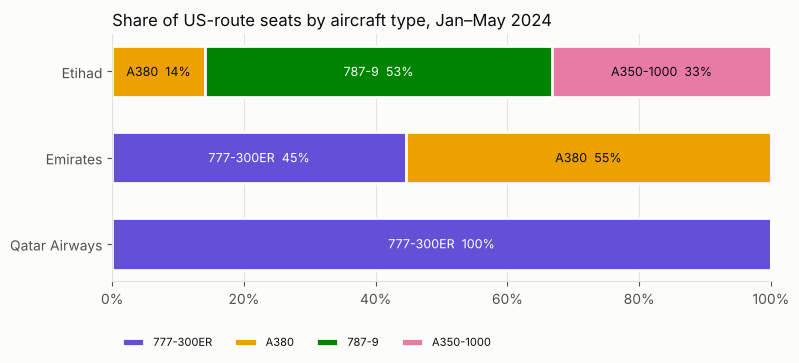

In [10]:
short = {'Boeing 777-300/300ER/333ER': '777-300ER', 'Airbus Industrie A380-800': 'A380', 'B787-900 Dreamliner': '787-9', 'Airbus 350-1000': 'A350-1000'}
win['ac_short'] = win['aircraft'].map(short).fillna(win['aircraft'])
mix = win.groupby(['carrier', 'ac_short'])['SEATS'].sum()
mix = (mix / mix.groupby(level=0).transform('sum')).unstack(fill_value=0)
mix = mix.loc[['Etihad', 'Emirates', 'Qatar Airways']]
mix = mix[mix.sum().sort_values(ascending=False).index]
# aircraft get their own hues (not the carrier colours) so colour never means two things
ac_cols = {'777-300ER': '#6250d6', 'A380': '#eda100', '787-9': '#008300', 'A350-1000': '#e87ba4'}
dark_text = {'A380', 'A350-1000'}

fig, ax = plt.subplots(figsize=(8.5, 3.2))
left = np.zeros(len(mix))
for k, a in enumerate(mix.columns):
    vals = mix[a].values
    ax.barh(mix.index, vals, left=left, color=ac_cols.get(a, '#9a9893'), edgecolor=SURF, lw=2, label=a, height=0.6)
    for i, v in enumerate(vals):
        if v > 0.1: ax.text(left[i] + v / 2, i, f'{a}  {v:.0%}', ha='center', va='center', fontsize=9,
                            color=INK if a in dark_text else 'white')
    left += vals
ax.set_axisbelow(True); ax.invert_yaxis(); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0)); ax.grid(axis='y', visible=False)
ax.set_title('Share of US-route seats by aircraft type, Jan–May 2024', loc='left', fontsize=12, color=INK)
ax.legend(frameon=False, bbox_to_anchor=(0, -0.18), loc='upper left', ncol=4, fontsize=8)
plt.savefig('../images/04_aircraft_mix.png'); plt.show()

**What this shows**

- **Chicago** runs Etihad's highest load factor (92.7%) on its largest aircraft (366 seats per departure, A350-1000 and A380). Even at that size it is nearly full, so it's the clearest candidate for extra capacity.
- **New York JFK** is Etihad's biggest US route, with two daily round trips mostly on the 787-9 plus some A350-1000 and A380 flights, at 88.2% load factor.
- Aircraft types are as reported to BTS; all Qatar Airways US flights in this extract are coded as 777-300ER.
- **Boston** launched at the end of March 2024 with about four weekly 787-9 flights, so its January–May averages understate it. Its load factor ramped from 78% in its first full month (April) to 96% in May, a fast start for a new route.

## 7. Key findings and recommendations

1. **Etihad's US routes are full; its network is narrow.** 89% load factor across 4 gateways, versus 11 each for its Gulf peers. Growth in the US is more likely to come from **new gateways or extra frequency** than from stimulating demand on existing routes.
2. **Chicago is the strongest capacity signal:** the highest load factor in both directions, on the biggest aircraft. **Boston's** quick ramp-up to 96% is a second one.
3. **Demand holds up in both directions** (the weaker direction stays above 80%, unlike Emirates' 60–70% return flights), so Etihad can sell in both the UAE and the US rather than relying on one point of sale.
4. **The March–April dip is sharpest for Etihad.** That's where pricing, **fare-brand upsell** and direct-channel campaigns can protect revenue, because when seats are hard to fill, earning more per passenger (yield) supports PRASK.
5. **Next step with internal data:** combine load factor with yield and booking-channel data (direct vs indirect) to calculate PRASK by route and test whether high-load-factor routes are also high-yield.

### Limitations
- T-100 contains no fares or revenue, so PRASK and yield can't be calculated here.
- Data covers flights touching the US only, and Jan–May 2024 only (the common reporting window). It says nothing about Etihad's wider network.
- Load factor shows demand, not profitability. Network decisions also depend on costs, aircraft availability and bilateral traffic rights.